In [1]:
import pandas as pd

In [2]:
url = 'https://raw.githubusercontent.com/codebasics/py/master/ML/9_decision_tree/salaries.csv'
df = pd.read_csv(url)

In [3]:
df

,company,job,degree,salary_more_then_100k
0,google,sales executive,bachelors,0
1,google,sales executive,masters,0
2,google,business manager,bachelors,1
3,google,business manager,masters,1
4,google,computer programmer,bachelors,0
5,google,computer programmer,masters,1
6,abc pharma,sales executive,masters,0
7,abc pharma,computer programmer,bachelors,0
8,abc pharma,business manager,bachelors,0
9,abc pharma,business manager,masters,1


In [4]:
inputs = df.drop(columns='salary_more_then_100k')
target = df['salary_more_then_100k']

In [5]:
inputs

,company,job,degree
0,google,sales executive,bachelors
1,google,sales executive,masters
2,google,business manager,bachelors
3,google,business manager,masters
4,google,computer programmer,bachelors
5,google,computer programmer,masters
6,abc pharma,sales executive,masters
7,abc pharma,computer programmer,bachelors
8,abc pharma,business manager,bachelors
9,abc pharma,business manager,masters


In [6]:
target

0     0
1     0
2     1
3     1
4     0
5     1
6     0
7     0
8     0
9     1
10    1
11    1
12    1
13    1
14    1
15    1
Name: salary_more_then_100k, dtype: int64

In [7]:
from sklearn.preprocessing import LabelEncoder
le_company = LabelEncoder()
le_job = LabelEncoder()
le_degree = LabelEncoder()

In [10]:
inputs['company_n'] = le_company.fit_transform(inputs['company'])
inputs['job_n'] = le_job.fit_transform(inputs['job'])
inputs['degree_n'] = le_degree.fit_transform(inputs['degree'])

In [11]:
inputs

,company,job,degree,company_n,job_n,degree_n
0,google,sales executive,bachelors,2,2,0
1,google,sales executive,masters,2,2,1
2,google,business manager,bachelors,2,0,0
3,google,business manager,masters,2,0,1
4,google,computer programmer,bachelors,2,1,0
5,google,computer programmer,masters,2,1,1
6,abc pharma,sales executive,masters,0,2,1
7,abc pharma,computer programmer,bachelors,0,1,0
8,abc pharma,business manager,bachelors,0,0,0
9,abc pharma,business manager,masters,0,0,1


In [12]:
inputs_n = inputs.drop(['company','job','degree'],axis='columns')

In [13]:
inputs_n

,company_n,job_n,degree_n
0,2,2,0
1,2,2,1
2,2,0,0
3,2,0,1
4,2,1,0
5,2,1,1
6,0,2,1
7,0,1,0
8,0,0,0
9,0,0,1


In [14]:
from sklearn import tree 
model = tree.DecisionTreeClassifier()

In [15]:
model.fit(inputs_n, target)

DecisionTreeClassifier()

In [16]:
model.score(inputs_n,target)

1.0

In [18]:
model.predict([[2,1,0]])

array([0], dtype=int64)

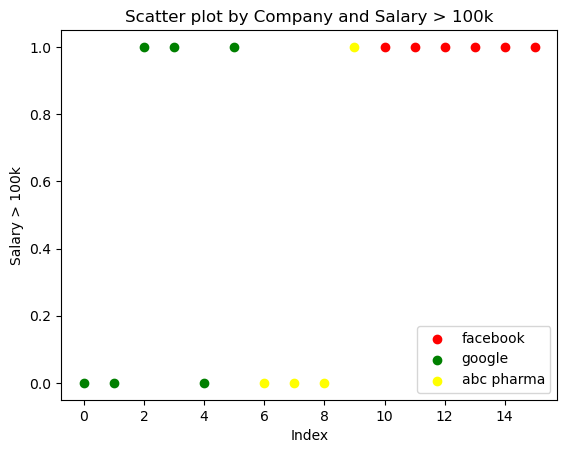

In [19]:
import matplotlib.pyplot as plt

data = {
    'company': ['google', 'google', 'google', 'google', 'google', 'google', 
                'abc pharma', 'abc pharma', 'abc pharma', 'abc pharma', 
                'facebook', 'facebook', 'facebook', 'facebook', 'facebook', 'facebook'],
    'job': ['sales executive', 'sales executive', 'business manager', 'business manager', 
            'computer programmer', 'computer programmer', 'sales executive', 
            'computer programmer', 'business manager', 'business manager', 
            'sales executive', 'sales executive', 'business manager', 
            'business manager', 'computer programmer', 'computer programmer'],
    'degree': ['bachelors', 'masters', 'bachelors', 'masters', 
               'bachelors', 'masters', 'masters', 'bachelors', 
               'bachelors', 'masters', 'bachelors', 'masters', 
               'bachelors', 'masters', 'bachelors', 'masters'],
    'salary_more_then_100k': [0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1]
}

color_map = {'facebook': 'red', 'google': 'green', 'abc pharma': 'yellow'}

for company in color_map.keys():
    x = [i for i in range(len(data['company'])) if data['company'][i] == company]
    y = [data['salary_more_then_100k'][i] for i in x]
    plt.scatter(x, y, color=color_map[company], label=company)

plt.xlabel('Index')
plt.ylabel('Salary > 100k')
plt.title('Scatter plot by Company and Salary > 100k')
plt.legend()

plt.show()